# Project data exploration
Using a dataset that your group is consider using for the term project, let's do some more data exploring of your dataset. The goal is to ask 5 unique, independent questions to understand your data.

Group name:  
Created by: Dan Nguyen  
Last updated: 10/29/26  

It contains data about discourses on AI-driven data scientists’ job displacement on LinkedIn. It was used for a Master Dissertation, DiCEM (Pompeu Fabra University, Barcelona), year 2024-2025 (http://hdl.handle.net/10230/71874). It is also referred in the article Technological optimism or automation anxiety: how data scientists discuss AI-driven job displacement, Hipertext.net, n. 32, May 2026.
Goal: explaining the perceptions and sentiments of data scientists - AI experts and practitioners - regarding AI's ability to displace them. To reach this goal, a sufficiently meaningful sample of 784 posts published from April 2024 to June 2025 on LinkedIn – a platform for professional development and networking – was scrutinised. With LDA topic modelling and zero-shot sentiment analysis, social media discourses on data scientists’ job displacement have been mapped. Data is contained in a spreadsheet, with raw text of Linkedin posts (anonymized), text after processing, and calculation of probability between topics.

Import your data. If you want to mount your Google drive you can use `from google.colab import drive` and `drive.mount('/content/drive')`

* **What is the dataset about?** LinkedIn posts written between April 2024 and June 2025 by data scientists and AI practitioners about whether AI could replace their jobs. It comes from Universitat Pompeu Fabra's research repository (DOI [10.34810/DATA3307](https://doi.org/10.34810/DATA3307), CC0 license) and supports the 2026 article *Technological optimism or automation anxiety: how data scientists discuss AI driven job displacement* (Hipertext.net, no. 32).
* **How large is it?** One CSV file (about 1.7 MB) with 784 posts and 9 columns: raw text, preprocessed text, and 7 topic probability columns. We added helper columns for post length, dominant topic, topic strength, and a simple tone label.
* **Initial concerns:** The file uses European formatting (semicolons and decimal commas) and has 215 blank rows at the end. 97 posts lost special characters (fancy Unicode letters and emojis became `?`). Topics are only numbered, so we named them ourselves. There is no date, author, or sentiment column, and 82% of posts fall in one topic, so the smaller topics have very few posts.
* **Main objective:** Fear of losing your job to AI is a growing source of workplace stress. We want to measure how the people who build AI talk about that fear: which concerns come up, how often posts sound anxious versus optimistic, and whether we can automatically detect anxious posts so this kind of stress can be tracked over time.


In [ ]:
# Load the data
import sys
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/CS133 group project/data/Dataset_LinkedIn_posts_Hipertext_32_def-1.csv'
else:
    DATA_PATH = '../data/Dataset_LinkedIn_posts_Hipertext_32_def-1.csv'

# The file uses semicolons between columns and commas as decimal points
raw = pd.read_csv(DATA_PATH, sep=';', decimal=',')
df = raw.dropna(how='all').copy()   # drop the blank rows at the end of the file
print('As loaded:', raw.shape, ' after dropping blank rows:', df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
As loaded: (999, 9)  after dropping blank rows: (784, 9)


Clean up column names and add helper columns (same setup as P1_initial_exploration, plus a simple tone measure).

In [ ]:
df = df.rename(columns={
    'Linkedin Raw text': 'raw_text',
    'LinkedIn post Text after pre-processing': 'clean_text'
})
df = df.rename(columns={col: 'Topic' + re.search(r'Topic\s*(\d+)', col).group(1)
                        for col in df.columns if col.startswith('Topic')})
topic_cols = [f'Topic{i}' for i in range(1, 8)]

topic_names = {
    'Topic1': 'Will AI replace us?',
    'Topic2': 'AutoML automating ML',
    'Topic3': 'Vibe coding with GenAI',
    'Topic4': 'ChatGPT doing analysis',
    'Topic5': 'LLM agents at work',
    'Topic6': 'Juniors and citizen devs',
    'Topic7': 'Engineering skills for AI era'
}
topic_order = list(topic_names.values())

df['post_length'] = df['raw_text'].astype(str).str.split().apply(
    lambda words: len([w for w in words if w.strip('?')]))   # ignore '?' only tokens
df['dominant_topic'] = df[topic_cols].idxmax(axis=1).map(topic_names)
df['topic_strength'] = df[topic_cols].max(axis=1)

# Simple word list tone measure (a first pass; the project will test a real sentiment model)
# 'replace' is left out on purpose: it is the subject of nearly every post, not a feeling.
anxiety_words = {'fear', 'afraid', 'scare', 'scary', 'worry', 'worried', 'anxiety', 'anxious',
                 'threat', 'threaten', 'layoff', 'lose', 'obsolete', 'panic', 'risk',
                 'unemployment', 'unemployed', 'cut', 'kill', 'dead', 'die', 'danger',
                 'dangerous', 'uncertain', 'uncertainty', 'struggle', 'stress', 'terrify'}
optimism_words = {'opportunity', 'augment', 'empower', 'excite', 'exciting', 'enhance', 'boost',
                  'growth', 'grow', 'benefit', 'innovation', 'improve', 'upskill', 'productivity',
                  'productive', 'collaborate', 'collaboration', 'thrive', 'potential', 'unlock',
                  'amplify', 'efficient', 'efficiency'}

tokens = df['clean_text'].astype(str).str.split()
df['anxiety_count'] = tokens.apply(lambda w: sum(x in anxiety_words for x in w))
df['optimism_count'] = tokens.apply(lambda w: sum(x in optimism_words for x in w))
df['tone'] = 'Balanced'
df.loc[df['optimism_count'] > df['anxiety_count'], 'tone'] = 'Optimistic'
df.loc[df['anxiety_count'] > df['optimism_count'], 'tone'] = 'Anxious'
tone_order = ['Optimistic', 'Balanced', 'Anxious']

df[['dominant_topic', 'post_length', 'anxiety_count', 'optimism_count', 'tone']].head()

,dominant_topic,post_length,anxiety_count,optimism_count,tone
0,Will AI replace us?,205,1,4,Optimistic
1,Will AI replace us?,254,1,0,Anxious
2,Will AI replace us?,399,1,3,Optimistic
3,LLM agents at work,291,3,0,Anxious
4,Will AI replace us?,269,1,3,Optimistic


### Q1: Show the first 5 lines of your data. Is your data format as expected or do you have to take into consideration how to handle data.

In [ ]:
raw.head()

,Linkedin Raw text,LinkedIn post Text after pre-processing,Topic1 (distribution of probabilities between topics),Topic2 (distribution of probabilities between topics),Topic3 (distribution of probabilities between topics),Topic4 (distribution of probabilities between topics),Topic5 (distribution of probabilities between topics),Topic6 (distribution of probabilities between topics),Topic7 (distribution of probabilities between topics)
0,I bumped into a friend who asked me how things...,bump friend who thing family project work rece...,0.9908,0.0015,0.0015,0.0015,0.0015,0.0015,0.0015
1,The Future of Data Analytics: Will AI Tools Re...,future analytic ai tool replace ai tool chatgp...,0.9933,0.0011,0.0011,0.0011,0.0011,0.0011,0.0011
2,I've been really interested to see the enormou...,really interested enormous wave discussion aro...,0.9643,0.0324,0.0007,0.0007,0.0007,0.0007,0.0007
3,???? ???????? ?????????????????????? ?????????...,ai generate code snippet second take build sca...,0.3223,0.0008,0.0008,0.0008,0.6736,0.0008,0.0008
4,Reinventing Yourself in the Age of AI \n\nAs a...,reinvent age ai artificial intelligence contin...,0.6730,0.0009,0.0009,0.0009,0.0009,0.0009,0.3223


In [ ]:
print(raw.dtypes)

Linkedin Raw text                                         object
LinkedIn post Text after pre-processing                   object
Topic1 (distribution of probabilities between topics)    float64
Topic2 (distribution of probabilities between topics)    float64
Topic3 (distribution of probabilities between topics)    float64
Topic4 (distribution of probabilities between topics)    float64
Topic5 (distribution of probabilities between topics)    float64
Topic6 (distribution of probabilities between topics)    float64
Topic7 (distribution of probabilities between topics)    float64
dtype: object


In [ ]:
print('Completely blank rows:', raw.isnull().all(axis=1).sum())
print('Posts with lost characters:', df['raw_text'].str.contains(r'\?{5,}').sum())

Completely blank rows: 215
Posts with lost characters: 97


The format was not as expected at first. With default settings, `pd.read_csv` fails because the file separates columns with semicolons. After adding `sep=';'` and `decimal=','` (values like `0,9643` use a comma as the decimal point) the 7 topic columns load as floats and the text columns as strings. Other things we had to handle:

* 215 completely blank rows at the bottom of the file, which we drop to get the 784 real posts.
* Very long column names, which we shorten to `raw_text`, `clean_text`, and `Topic1` to `Topic7`.
* Raw text that contains `\n` line breaks and, in 97 posts, runs of `?` where special characters were lost. The `clean_text` column is already lowercased, lemmatized, and stripped of stop words, so we use it for word counts and the raw text for post length.

### Q2: Filtering data.
**Question:** Which posts use more anxiety words than optimism words, and which topics do they come from?


In [ ]:
anxious = df[df['anxiety_count'] > df['optimism_count']]
print(f'Anxious posts: {len(anxious)} of {len(df)} ({len(anxious) / len(df):.0%})')

summary = pd.DataFrame({
    'all_posts': df['dominant_topic'].value_counts(),
    'anxious_posts': anxious['dominant_topic'].value_counts()
}).fillna(0).astype(int)
summary['percent_anxious'] = (summary['anxious_posts'] / summary['all_posts'] * 100).round(1)
summary.sort_values('all_posts', ascending=False)

Anxious posts: 149 of 784 (19%)


,all_posts,anxious_posts,percent_anxious
dominant_topic,,,
Will AI replace us?,642,118,18.4
LLM agents at work,67,16,23.9
AutoML automating ML,23,2,8.7
ChatGPT doing analysis,17,6,35.3
Vibe coding with GenAI,13,4,30.8
Engineering skills for AI era,11,1,9.1
Juniors and citizen devs,11,2,18.2


In [ ]:
# Posts that explicitly talk about layoffs
layoff_posts = df[df['raw_text'].str.contains('layoff|laid off', case=False)]
print('Posts that mention layoffs:', len(layoff_posts))

# The most anxious posts
anxious.sort_values('anxiety_count', ascending=False)[['dominant_topic', 'anxiety_count', 'optimism_count', 'clean_text']].head(5)

Posts that mention layoffs: 9


,dominant_topic,anxiety_count,optimism_count,clean_text
350,Will AI replace us?,8,1,microsoft layoff not blame ai understand shift...
747,Will AI replace us?,7,4,ai another calculator smarter calculator first...
277,Will AI replace us?,6,1,ai not mind tool ai vs human intelligence diff...
133,Will AI replace us?,6,5,young person early science career gen ai write...
49,Will AI replace us?,5,1,although side defend ai not replace night scar...


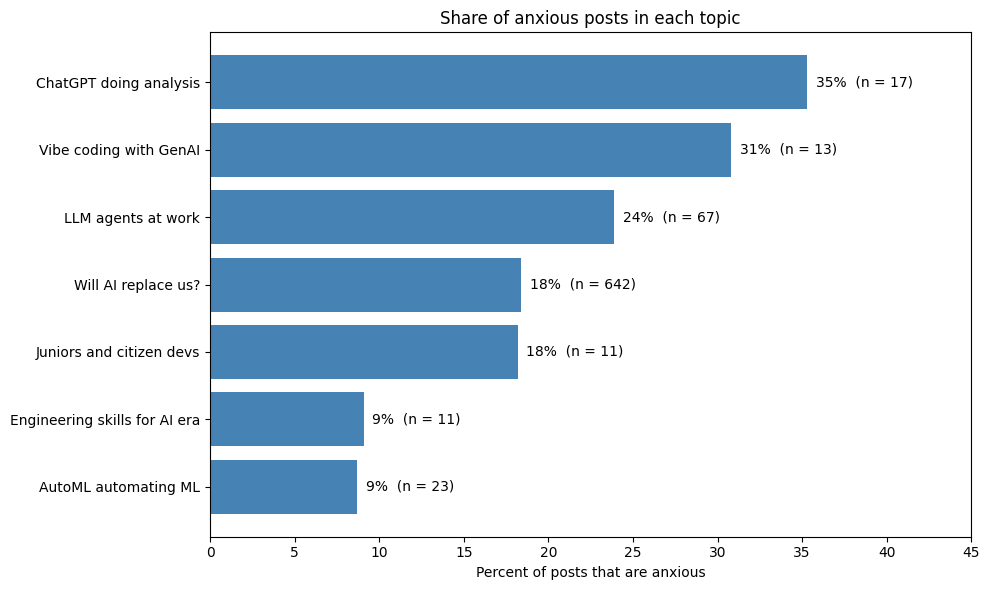

In [ ]:
plot_data = summary.sort_values('percent_anxious')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data.index, plot_data['percent_anxious'], color='steelblue')

# label each bar with its percent and how many posts are in that topic
for i, (pct, n) in enumerate(zip(plot_data['percent_anxious'], plot_data['all_posts'])):
    ax.text(pct + 0.5, i, f'{pct:.0f}%  (n = {n})', va='center')

ax.set_xlabel('Percent of posts that are anxious')
ax.set_title('Share of anxious posts in each topic')
ax.set_xlim(0, 45)
plt.tight_layout()
plt.show()

Only about 1 in 5 posts uses more anxiety words than optimism words. Most anxious posts come from *Will AI replace us?* simply because that topic is so large, but by percentage the smaller technical topics such as *Vibe coding with GenAI* and *ChatGPT doing analysis* lean more anxious, while *AutoML automating ML* and *Engineering skills for AI era* are the least anxious. Only 9 posts mention layoffs directly, which suggests the anxiety in these posts is mostly about the future, not about job losses that already happened. With so few posts in the small topics, these percentages are rough and need a better sentiment model to confirm.

### Q3: Scatter plot.
**Question:** Do posts that use more anxiety words also use more optimism words, or does each post lean one way?

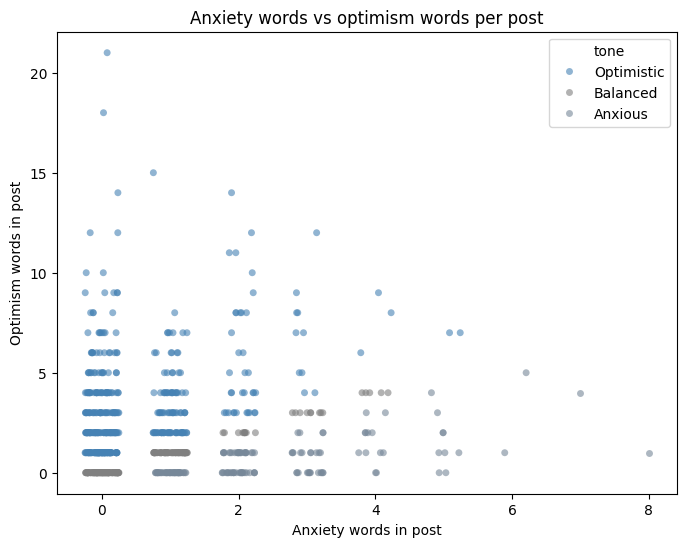

Correlation: 0.06


In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
tone_order = ['Optimistic', 'Balanced', 'Anxious']
tone_colors = {'Optimistic': 'steelblue', 'Balanced': 'grey', 'Anxious': 'lightslategrey'}
sns.stripplot(data=df, x='anxiety_count', y='optimism_count', hue='tone', hue_order=tone_order,
              palette=tone_colors,
              jitter=0.25, alpha=0.6, size=5, native_scale=True, ax=ax)
ax.set_xlabel('Anxiety words in post')
ax.set_ylabel('Optimism words in post')
ax.set_title('Anxiety words vs optimism words per post')
plt.show()

print('Correlation:', round(df['anxiety_count'].corr(df['optimism_count']), 2))

The two counts are barely related (correlation about 0.06), so using fear words does not stop a post from also using hopeful words. About 40% of posts sit in the lower left corner with at most one emotion word of each kind, and the optimistic points stretch much higher up the y axis (up to 21 optimism words) than the anxious ones go along the x axis (at most 8). A common pattern on LinkedIn seems to be naming the fear and then answering it with a hopeful message, which is exactly the kind of mixed post a simple word count will struggle to label correctly.

 ## Q4: Distribution

 Visualize a non-numerical variable (or convert one of your numeric variable to a category) and look at their distribution. What are your observations based on the output plot?

 We converted the two word counts into a category, `tone` (Optimistic, Balanced, or Anxious), and look at its distribution overall and within the two largest topics.

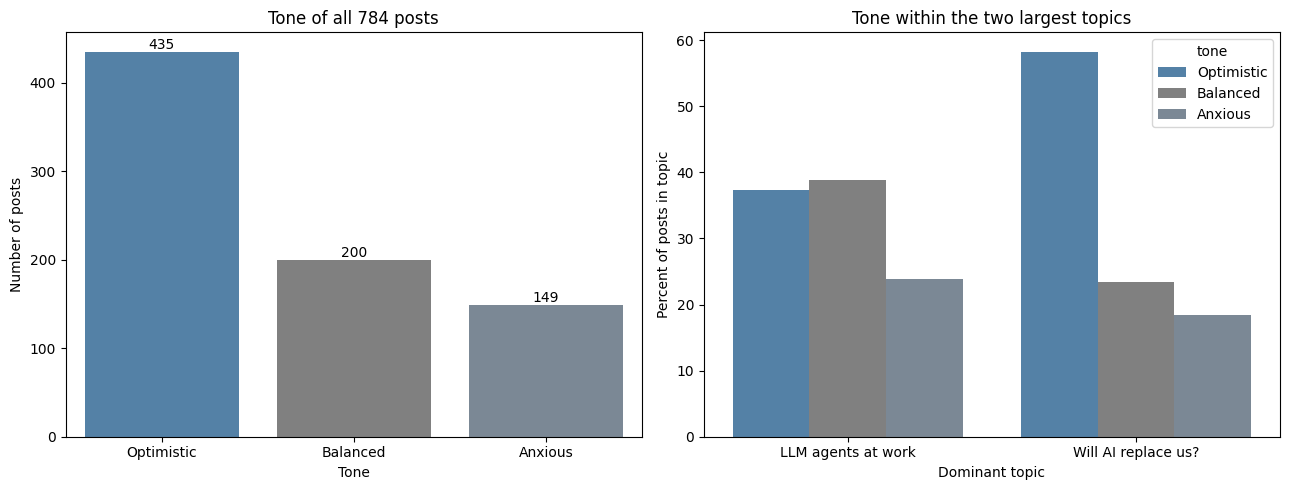

,proportion
tone,
Optimistic,55.5
Balanced,25.5
Anxious,19.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, x='tone', hue='tone', legend=False, order=tone_order, ax=axes[0],
              palette=tone_colors)
axes[0].set_title('Tone of all 784 posts')
axes[0].set_xlabel('Tone')
axes[0].set_ylabel('Number of posts')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha='center', va='bottom')

top_topics = ['Will AI replace us?', 'LLM agents at work']
share = (df[df['dominant_topic'].isin(top_topics)]
         .groupby('dominant_topic')['tone'].value_counts(normalize=True)
         .mul(100).rename('percent').reset_index())
sns.barplot(data=share, x='dominant_topic', y='percent', hue='tone', hue_order=tone_order,
            palette=tone_colors, ax=axes[1])
axes[1].set_title('Tone within the two largest topics')
axes[1].set_xlabel('Dominant topic')
axes[1].set_ylabel('Percent of posts in topic')
plt.tight_layout()
plt.show()

df['tone'].value_counts(normalize=True).mul(100).round(1)

Optimistic posts are the clear majority (about 55%), followed by balanced posts (about 26%) and anxious posts (about 19%). This matches the article's conclusion that data scientists mostly see AI as a tool that augments their work, with a smaller group worried about layoffs. Inside the two biggest topics the tone differs: *LLM agents at work* has more anxious posts (24% vs 18%) and far fewer optimistic ones (37% vs 58%) than the general *Will AI replace us?* debate, so talk about autonomous agents seems to carry more worry than general AI talk.

### Q5: Interactive line plot
**Question:** As posts get longer, does the density of anxiety and optimism words change? Hover shows how many posts are in each length group.

In [ ]:
bins = list(range(0, 451, 50)) + [600]
labels = [f'{b}-{b + 50}' for b in range(0, 450, 50)] + ['450+']
df['length_group'] = pd.cut(df['post_length'], bins=bins, labels=labels)

clean_len = tokens.str.len()
df['anxiety_per_100'] = df['anxiety_count'] / clean_len * 100
df['optimism_per_100'] = df['optimism_count'] / clean_len * 100

trend = (df.groupby('length_group', observed=True)
           .agg(posts=('post_length', 'size'),
                anxiety=('anxiety_per_100', 'mean'),
                optimism=('optimism_per_100', 'mean'))
           .reset_index())
trend_long = trend.melt(id_vars=['length_group', 'posts'], value_vars=['anxiety', 'optimism'],
                        var_name='word_type', value_name='words_per_100')

fig = px.line(trend_long, x='length_group', y='words_per_100', color='word_type', markers=True,
              hover_data={'posts': True, 'words_per_100': ':.2f'},
              color_discrete_map={'anxiety': 'tomato', 'optimism': 'seagreen'},
              labels={'length_group': 'Post length (words)',
                      'words_per_100': 'Emotion words per 100 words',
                      'word_type': 'Word type', 'posts': 'Posts in group'},
              title='Anxiety and optimism word density by post length')
fig.show()
trend.round(2)

,length_group,posts,anxiety,optimism
0,0-50,27,1.96,2.56
1,50-100,101,1.50,2.71
2,100-150,169,1.04,2.44
3,150-200,140,0.88,1.90
4,200-250,98,0.67,2.12
5,250-300,73,0.99,1.91
6,300-350,73,0.66,1.94
7,350-400,47,0.72,1.82
8,400-450,43,0.57,1.75
9,450+,13,1.05,0.70


Optimism words are denser than anxiety words in every length group except the last one, which has only 13 posts. Both lines slope down as posts get longer: short posts (under 150 words) pack in the most emotional language, while long posts spend more of their words on explanation, examples, and technical detail. Hovering shows that the groups past 400 words contain few posts, so the end of the trend is less reliable.

### Q6: Provide some EDA questions
Without plotting at this time. Think of 5 unique, independent questions that you can explore with this dataset.

1. **Which words best separate anxious posts from optimistic ones?** Compare the most frequent and most distinctive words (TF-IDF) in each group to see what people are actually afraid of, for example agents, junior roles, or layoffs.
2. **Does a post's dominant topic predict its tone?** Test whether the share of anxious posts really differs between topics (for example with a chi square test), instead of relying on small raw counts.
3. **Do posts that mention specific roles (junior, analyst, engineer, scientist) sound more anxious than posts about the field in general?**
4. **Do posts about learning and upskilling sound more optimistic than posts that never mention new skills?** This tests whether "keep learning" is how people cope with the fear.
5. **How well does our simple word list agree with a real sentiment model?** Label the posts with a zero shot transformer model and compare it with the word list labels to see where they disagree, especially on mixed posts.


### Q7: Challenges
What are some of the challenges you are currently facing in your project? Are there any particular coding related application or topic that you believe could help you further push your project forward?

* **No labels.** The paper ran sentiment analysis, but the CSV only contains text and topic probabilities. Our tone label comes from a short word list, which misses sarcasm, negation ("AI will **not** replace you"), and posts that name a fear only to argue against it.
* **Small and unbalanced data.** 784 posts in total, 82% in one topic, and five topics with 11 to 23 posts, so results about small topics are not reliable.
* **No dates or authors.** We cannot study how the mood changed over time or around events like big layoff announcements, and cannot compare job titles or countries.
* **Messy text.** 97 posts lost special characters, and the CSV needed special settings to load.
* **Topic names are our interpretation.** We named the LDA topics from their top words, so another person could label them differently.

**What would help**
* NLP with **Hugging Face transformers**, especially zero shot classification and pretrained sentiment and emotion models, so we can label posts without hand labeling all of them.
* Text classification with **scikit-learn** (TF-IDF with logistic regression) and how to evaluate it properly with a small hand labeled test set.
* Building interactive dashboards (for example **Plotly Dash** or **Streamlit**) to present the final results.